# 05 – Street network (built form / access)

**Goal:** describe the street pattern of each cell: how much street there is, how connected it is (intersections vs dead ends), how fine the grid is, how much is main road and how much is footpath/cycleway.

- **Input:** Geofabrik OSM extract for Slovenia, `data/raw/OSM/gis_osm_roads_free_1` + `data/processed/cells.gpkg`
- **Output:** `data/processed/ind_streets.csv`

**Indicators per cell:**

| column | meaning | why it matters |
|---|---|---|
| `str_length` | street length in the cell (m per hectare) | how much street there is |
| `str_intersections` | number of street intersections (3+ streets meet) | connectivity, walkability |
| `str_dead_ends` | number of street dead ends | cul-de-sac suburbs vs connected grid |
| `str_segment_median` | median length of street segments between intersections (m) | fine old-town grain vs long rural roads |
| `str_main_share` | share of street length on main roads (motorway–secondary) | traffic corridors |
| `str_path_share` | footpath + cycleway length / (street + path length) | walking/cycling infrastructure, parks |

## 1. Setup

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "OSM"
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "figures"

CELL_AREA = 100 * 100      # m²
BUFFER = 200               # m around MOL, so features on the border are not cut off

## 2. Load the study area and grid

In [2]:
mol = gpd.read_file(ROOT / "data" / "raw" / "LJ_prebivalstvo_MOL_100m_2025" / "obcina_ljubljana.gpkg").to_crs(3794)
cells = gpd.read_file(PROCESSED / "cells.gpkg", layer="cells")
assert cells.crs.to_epsg() == 3794
grid = cells[["cell_id", "geometry"]]

# The Geofabrik files cover all of Slovenia. We read only what lies in MOL + buffer (mask is in the files' CRS, EPSG:4326).
area_4326 = gpd.GeoSeries([mol.union_all().buffer(BUFFER)], crs=3794).to_crs(4326)
print((RAW / "PREBERI.txt").read_text(encoding="utf-8").strip())
print(f"MOL {mol.area.sum() / 1e6:.0f} km², grid {len(cells):,} cells")

OSM data downloaded on 30.10.2026
MOL 275 km², grid 27,505 cells


## 3. Load roads and split them into streets and paths
Geofabrik gives every road a type (`fclass`). We use two groups:
- **streets** (roads for vehicles, plus pedestrian zones and living streets): used for length, intersections, dead ends, segments, main-road share
- **paths** (footway, path, cycleway, steps): used only for the path share

**Left out:**
- `track*` and `bridleway`: forest/field roads, otherwise forests would look like they have many streets
- `service`: in OSM these are parking aisles, driveways and yard roads, and Geofabrik doesn't tell them apart. They would add thousands of fake intersections and dead ends in car parks.

Why paths are not used for intersections: footways include sidewalks and zebra crossings drawn as separate lines. Every crossing would count as an intersection, so the centre would look far more connected than it is.

In [3]:
STREET = ["motorway", "motorway_link", "trunk", "trunk_link", "primary", "primary_link", "secondary", "secondary_link",
          "tertiary", "tertiary_link", "unclassified", "residential", "living_street", "pedestrian"]
MAIN = ["motorway", "motorway_link", "trunk", "trunk_link", "primary", "primary_link", "secondary", "secondary_link"]
PATH = ["footway", "path", "cycleway", "steps"]

roads = gpd.read_file(RAW / "gis_osm_roads_free_1.shp", mask=area_4326)
print("All road types in MOL + buffer:", roads["fclass"].value_counts().to_dict())

roads = roads[roads["fclass"].isin(STREET + PATH)].reset_index(drop=True)
roads["is_street"] = roads["fclass"].isin(STREET)

All road types in MOL + buffer: {'service': 14709, 'footway': 12626, 'path': 5338, 'cycleway': 3733, 'residential': 3721, 'tertiary': 1405, 'track': 1266, 'secondary': 1142, 'steps': 1110, 'primary': 1073, 'unclassified': 1073, 'track_grade4': 848, 'track_grade5': 530, 'pedestrian': 496, 'track_grade3': 460, 'track_grade2': 351, 'motorway': 260, 'motorway_link': 232, 'track_grade1': 125, 'primary_link': 116, 'living_street': 93, 'secondary_link': 54, 'trunk_link': 51, 'trunk': 42, 'tertiary_link': 18, 'bridleway': 2}


## 4. Build the network: find intersections and dead ends
In OSM, a road is a line through a list of points (nodes). Two roads that meet **share a node** (same coordinates). Roads crossing on a bridge or in a tunnel don't share a node, so they are correctly *not* an intersection.

For each node we count how many street ends meet there (its **degree**):
- the first and last point of a line count 1 (one street end)
- a point in the middle of a line counts 2 (the street goes in and out)
- degree 1 = dead end, degree 2 = just a bend or a joint between two lines, degree ≥ 3 = intersection

We count in the original longitude/latitude coordinates, where shared nodes have exactly the same numbers.

In [4]:
import shapely

street_lines = roads.loc[roads["is_street"]].geometry.reset_index(drop=True)
coords, line_idx = shapely.get_coordinates(street_lines.values, return_index=True)
nodes = pd.DataFrame({"x": coords[:, 0].round(7), "y": coords[:, 1].round(7), "line": line_idx})

pos = nodes.groupby("line").cumcount()
n_pts = nodes.groupby("line")["line"].transform("size")
nodes["end"] = (pos == 0) | (pos == n_pts - 1)
nodes["incidence"] = np.where(nodes["end"], 1, 2)
nodes["pos"] = pos

degree = nodes.groupby(["x", "y"])["incidence"].sum().rename("degree").reset_index()
print(degree["degree"].value_counts().sort_index().to_dict())

{1: 1952, 2: 61369, 3: 4322, 4: 690, 5: 20, 6: 1}


A big junction or a dual carriageway is drawn as several intersection nodes a few metres apart.
We merge intersection nodes closer than **10 m** into one intersection, otherwise one junction would count as 2–4.

In [5]:
def to_points(df):
    return gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df["x"], df["y"]), crs=4326).to_crs(3794)

raw_inter = to_points(degree[degree["degree"] >= 3])
merged = raw_inter.buffer(5).union_all()           # nodes within 10 m touch each other
intersections = gpd.GeoDataFrame(
    geometry=gpd.GeoSeries([merged], crs=3794).explode(index_parts=False).centroid.reset_index(drop=True))
dead_ends = to_points(degree[degree["degree"] == 1])
print(f"{len(intersections):,} intersections (from {len(raw_inter):,} nodes), {len(dead_ends):,} dead ends")

4,677 intersections (from 5,033 nodes), 1,952 dead ends


## 5. Street segments
A **segment** is a piece of street between two intersections or dead ends. OSM lines don't follow this: one line can pass several intersections, and one street can be drawn as several lines.
We cut every street line at its interior intersection nodes and measure the pieces.
(Two lines that just continue each other at a degree-2 node stay two segments; this makes `str_segment_median` slightly shorter but affects all areas alike.)

In [6]:
nodes = nodes.merge(degree, on=["x", "y"], how="left")
cut = nodes[(~nodes["end"]) & (nodes["degree"] >= 3)]
cuts_per_line = cut.groupby("line")["pos"].apply(list).to_dict()

streets_m = street_lines.to_crs(3794)
seg_geoms, seg_line = [], []
for i, geom in enumerate(streets_m.values):
    pts = shapely.get_coordinates(geom)
    bounds = [0] + cuts_per_line.get(i, []) + [len(pts) - 1]
    for a, b in zip(bounds[:-1], bounds[1:]):
        seg_geoms.append(shapely.LineString(pts[a:b + 1]))
        seg_line.append(i)

segments = gpd.GeoDataFrame({"seg_length": shapely.length(seg_geoms)}, geometry=seg_geoms, crs=3794)
segments["fclass"] = roads.loc[roads["is_street"], "fclass"].values[seg_line]
print(f"{len(street_lines):,} street lines -> {len(segments):,} segments, median {segments['seg_length'].median():.0f} m")

9,776 street lines -> 12,926 segments, median 57 m


## 6. Cut streets and paths along cell borders
Like buildings, a street usually crosses several cells. We cut every segment (and every path) along the grid lines so that each cell gets exactly the length inside it.

In [7]:
paths = roads.loc[~roads["is_street"], ["fclass", "geometry"]].to_crs(3794)
lines = pd.concat([segments[["fclass", "geometry"]].assign(kind="street"),
                   paths.assign(kind="path")], ignore_index=True)
lines["seg_length"] = lines.length

pairs = gpd.sjoin(lines, grid, predicate="intersects")
pieces = pd.DataFrame({
    "cell_id": pairs["cell_id"].values,
    "line": pairs.index.values,
    "kind": pairs["kind"].values,
    "fclass": pairs["fclass"].values,
    "seg_length": pairs["seg_length"].values,
    "piece_length": shapely.length(shapely.intersection(
        pairs.geometry.values, grid.geometry.loc[pairs["index_right"]].values)),
})
pieces = pieces[pieces["piece_length"] > 0]

inside = lines.clip(mol).length.sum()
print(f"Length inside MOL kept: {pieces['piece_length'].sum() / inside:.1%}")

Length inside MOL kept: 99.9%


## 7. Indicators per cell

In [8]:
st = pieces[pieces["kind"] == "street"]
street_len = st.groupby("cell_id")["piece_length"].sum()
main_len = st[st["fclass"].isin(MAIN)].groupby("cell_id")["piece_length"].sum()
path_len = pieces[pieces["kind"] == "path"].groupby("cell_id")["piece_length"].sum()

def count_in_cells(points):
    j = gpd.sjoin(points[["geometry"]], grid, predicate="intersects")
    j = j[~j.index.duplicated()]
    return j.groupby("cell_id").size()

ind = pd.DataFrame({
    "str_length": street_len / (CELL_AREA / 10_000),                 # m per hectare (= m per cell)
    "str_intersections": count_in_cells(intersections),
    "str_dead_ends": count_in_cells(dead_ends),
    # Segment length uses the whole segment, not the piece (like footprint size in 02_buildings)
    "str_segment_median": st.drop_duplicates(["cell_id", "line"]).groupby("cell_id")["seg_length"].median(),
    "str_main_share": main_len.reindex(street_len.index, fill_value=0) / street_len,
})
total_len = street_len.add(path_len, fill_value=0)
ind["str_path_share"] = path_len.reindex(total_len.index, fill_value=0) / total_len

## 8. Combine and handle empty cells
- cells with no street: length, intersections, dead ends = 0 (OSM covers all of MOL, so "no street" really means no street)
- `str_segment_median`, `str_main_share` stay **NaN** without streets; `str_path_share` stays NaN without streets and paths. They are undefined there.

In [9]:
cols = ["str_length", "str_intersections", "str_dead_ends", "str_segment_median", "str_main_share", "str_path_share"]
result = grid[["cell_id"]].set_index("cell_id").join(ind)[cols]
for col in ["str_length", "str_intersections", "str_dead_ends"]:
    result[col] = result[col].fillna(0)
result[["str_intersections", "str_dead_ends"]] = result[["str_intersections", "str_dead_ends"]].astype(int)

print(f"Cells with streets: {(result['str_length'] > 0).sum():,} of {len(result):,}")
result.describe().round(2).T

Cells with streets: 9,641 of 27,505


,count,mean,std,min,25%,50%,75%,max
str_length,27505.0,45.56,81.32,0.00,0.0,0.00,83.81,927.24
str_intersections,27505.0,0.17,0.59,0.00,0.0,0.00,0.00,13.00
str_dead_ends,27505.0,0.07,0.31,0.00,0.0,0.00,0.00,6.00
str_segment_median,9641.0,373.31,548.33,3.37,95.0,193.21,429.15,6108.25
str_main_share,9641.0,0.18,0.36,0.00,0.0,0.00,0.00,1.00
str_path_share,9641.0,0.23,0.30,0.00,0.0,0.00,0.50,1.00


## 9. Sanity checks
The cells with the most intersections should be the old town / dense centre grid.

In [10]:
result.nlargest(10, "str_intersections").join(cells.set_index("cell_id")[["E", "N"]]).round(2)

,str_length,str_intersections,str_dead_ends,str_segment_median,str_main_share,str_path_share,E,N
cell_id,,,,,,,,
SIHM100_4617_1010,661.84,13,2,24.16,0.00,0.07,461700,101000
SIHM100_4639_980,927.24,11,0,18.99,0.17,0.31,463900,98000
SIHM100_4572_1015,379.73,10,0,20.28,0.00,0.00,457200,101500
SIHM100_4651_1025,644.70,9,0,19.84,0.75,0.36,465100,102500
SIHM100_4657_1031,829.98,9,0,13.82,0.82,0.19,465700,103100
SIHM100_4561_987,514.98,8,0,21.55,0.91,0.28,456100,98700
SIHM100_4657_1025,675.03,8,0,13.41,0.79,0.28,465700,102500
SIHM100_4649_1027,339.78,8,0,15.90,0.00,0.48,464900,102700
SIHM100_4646_1028,341.70,8,0,19.09,0.00,0.47,464600,102800


## 10. Maps

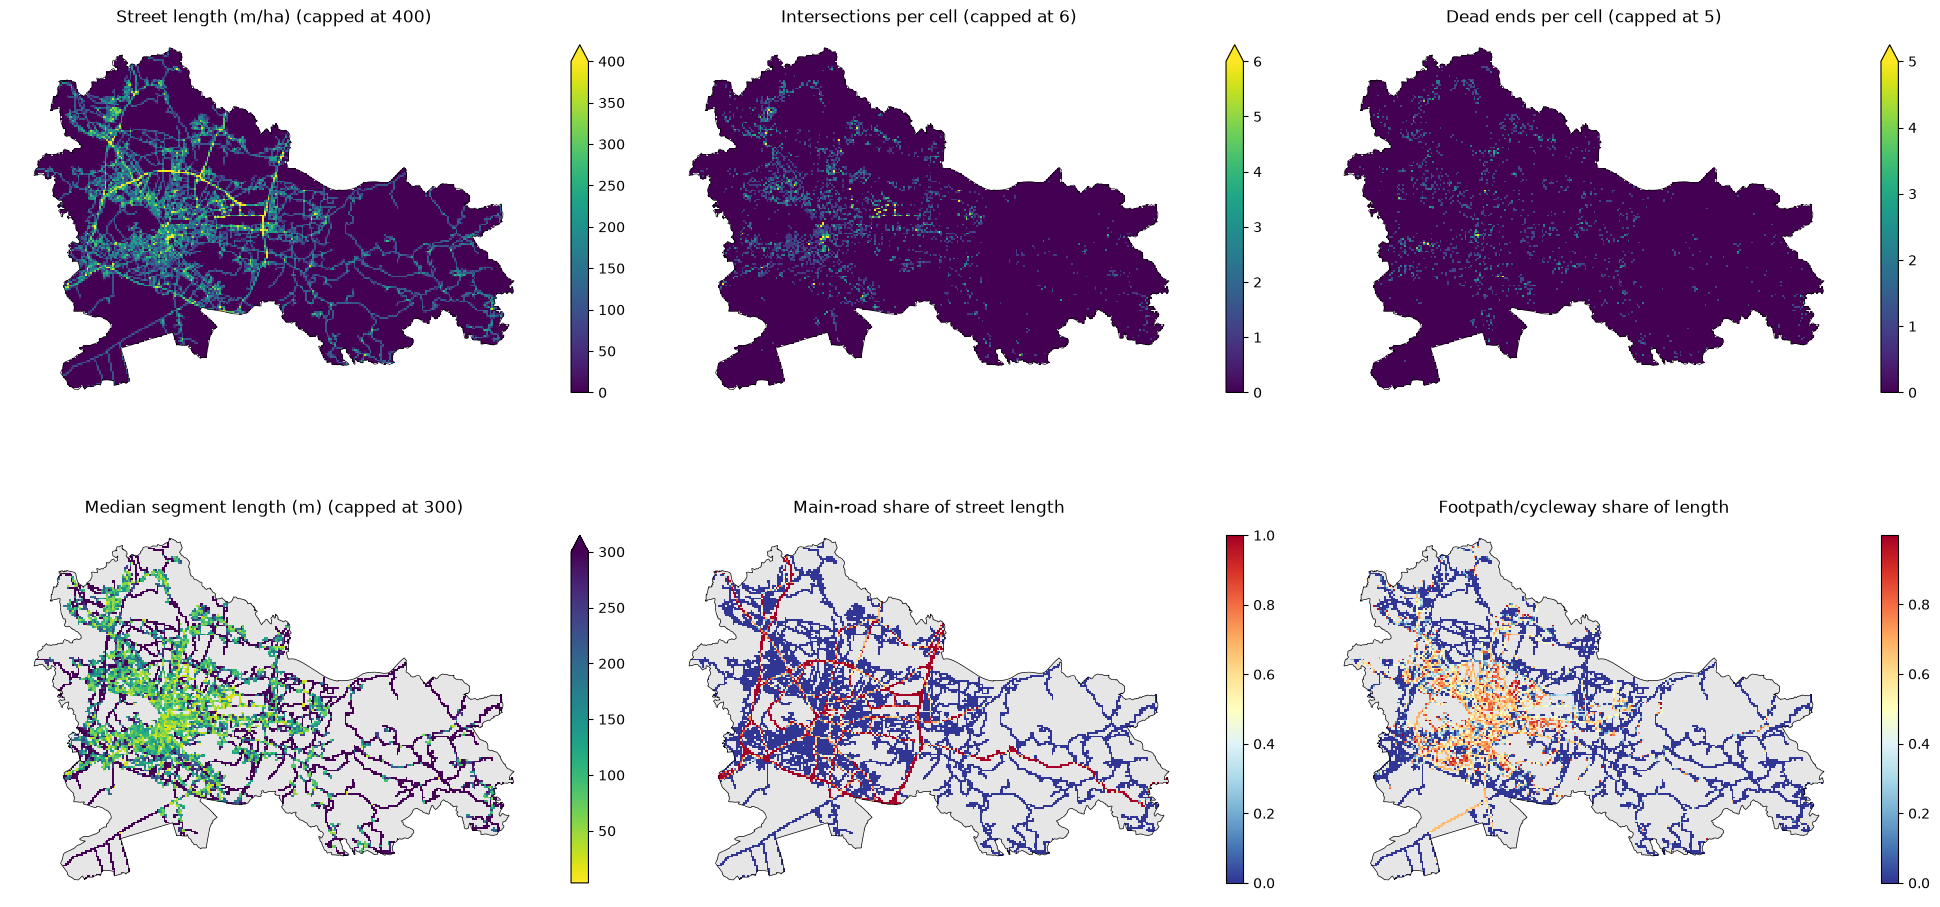

In [11]:
gdf = grid.merge(result.reset_index(), on="cell_id")

maps = [
    ("str_length", "Street length (m/ha)", "viridis", 400),
    ("str_intersections", "Intersections per cell", "viridis", 6),
    ("str_dead_ends", "Dead ends per cell", "viridis", 5),
    ("str_segment_median", "Median segment length (m)", "viridis_r", 300),
    ("str_main_share", "Main-road share of street length", "RdYlBu_r", None),
    ("str_path_share", "Footpath/cycleway share of length", "RdYlBu_r", None),
]
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
for ax, (col, title, cmap, vmax) in zip(axes.flat, maps):
    gdf.plot(ax=ax, color="#e6e6e6", linewidth=0)
    gdf.dropna(subset=[col]).plot(ax=ax, column=col, cmap=cmap, vmax=vmax, linewidth=0,
                                  legend=True, legend_kwds={"shrink": 0.6})
    mol.boundary.plot(ax=ax, color="black", linewidth=0.5)
    ax.set_title(title + (f" (capped at {vmax})" if vmax else ""))
    ax.set_axis_off()
plt.tight_layout()
fig.savefig(FIGURES / "05_streets.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. How do the indicators relate?
Street length and intersections are probably strongly correlated; if so, we keep one or combine them before clustering.

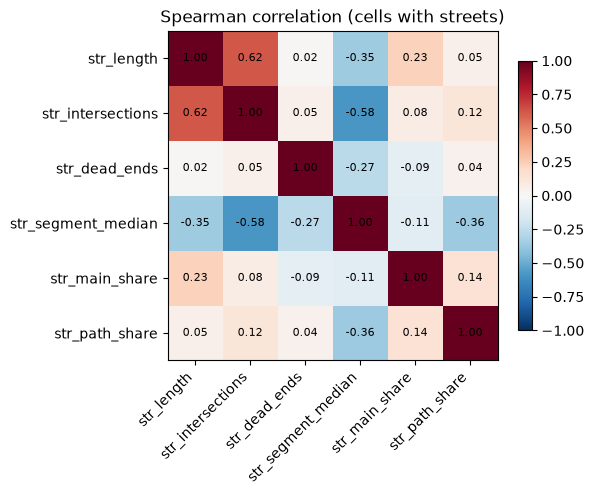

In [12]:
corr = result[result["str_length"] > 0][cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right")
ax.set_yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Spearman correlation (cells with streets)")
plt.tight_layout()
plt.show()

## 12. Save

In [13]:
out = result.reset_index()
out.to_csv(PROCESSED / "ind_streets.csv", index=False)
print(f"Saved {len(out):,} rows to {PROCESSED / 'ind_streets.csv'}")

Saved 27,505 rows to C:\Users\Maks\Desktop\Maks_šola\FRI\masters\urban-analysis\data\processed\ind_streets.csv


## Summary
- Six street indicators per cell, saved to `data/processed/ind_streets.csv`.

**Limitations to note in the thesis:**
- `service` roads are excluded because Geofabrik doesn't separate parking aisles/driveways from real access roads. Some short access roads to apartment blocks are therefore missing, and a street that continues as a service road counts as a dead end.
- Footways include sidewalks drawn as separate lines, so `str_path_share` is higher along well-mapped main streets in the centre.
- The 10 m tolerance for merging junction nodes is a choice; large motorway interchanges still count as several intersections.